<a href="https://colab.research.google.com/github/192565033simats-png/machine_learning/blob/main/Machine_Learning_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# EXP-1
import pandas as pd

# Training dataset
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Weak'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

print("Training Data:")
print(df)

# FIND-S Algorithm
hypothesis = ['0'] * (len(df.columns) - 1)

for i in range(len(df)):
    if df.iloc[i, -1] == 'Yes':
        for j in range(len(hypothesis)):

            if hypothesis[j] == '0':
                hypothesis[j] = df.iloc[i, j]

            elif hypothesis[j] != df.iloc[i, j]:
                hypothesis[j] = '?'

print("\nMost Specific Hypothesis:")
print(hypothesis)

Training Data:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High    Weak  Cool   Change        Yes

Most Specific Hypothesis:
['Sunny', 'Warm', '?', '?', '?', '?']


In [ ]:
# EXP-2
import pandas as pd

# ---------------------------------------------------
# STEP 1: Create Training Dataset
# ---------------------------------------------------

data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Weak'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

# Save dataset as CSV
df.to_csv('training_data.csv', index=False)

print("Training data saved as training_data.csv")
print("\nTraining Data:")
print(df)


# ---------------------------------------------------
# STEP 2: Read CSV File
# ---------------------------------------------------

data = pd.read_csv('training_data.csv')

X = data.iloc[:, :-1].values
Y = data.iloc[:, -1].values

attributes = list(data.columns[:-1])
n = len(attributes)


# ---------------------------------------------------
# STEP 3: Initialize S and G
# ---------------------------------------------------

# Most Specific Hypothesis
S = ['0'] * n

# Most General Hypothesis
G = [['?'] * n]


# ---------------------------------------------------
# STEP 4: Candidate-Elimination Algorithm
# ---------------------------------------------------

for i in range(len(X)):

    example = X[i]
    label = Y[i]

    print("\n----------------------------------------")
    print("Example", i + 1, ":", list(example), "=>", label)

    # -----------------------------------------------
    # POSITIVE EXAMPLE
    # -----------------------------------------------
    if label == 'Yes':

        # Remove hypotheses from G that do not cover
        # the positive example
        G = [
            g for g in G
            if all(g[j] == '?' or g[j] == example[j]
                   for j in range(n))
        ]

        # Generalize S
        for j in range(n):

            if S[j] == '0':
                S[j] = example[j]

            elif S[j] != example[j]:
                S[j] = '?'

    # -----------------------------------------------
    # NEGATIVE EXAMPLE
    # -----------------------------------------------
    else:

        new_G = []

        for g in G:

            # Check whether G covers the negative example
            covers_negative = all(
                g[j] == '?' or g[j] == example[j]
                for j in range(n)
            )

            if covers_negative:

                # Specialize G using S
                for j in range(n):

                    if S[j] != '0' and S[j] != '?' \
                            and S[j] != example[j]:

                        new_g = g.copy()
                        new_g[j] = S[j]

                        # Keep only hypotheses consistent
                        # with S
                        if new_g not in new_G:
                            new_G.append(new_g)

            else:
                new_G.append(g)

        G = new_G

    print("Specific Boundary (S):")
    print(S)

    print("General Boundary (G):")
    for g in G:
        print(g)


# ---------------------------------------------------
# STEP 5: Final Result
# ---------------------------------------------------

print("\n========================================")
print("FINAL RESULT")
print("========================================")

print("\nMost Specific Hypothesis (S):")
print(S)

print("\nSet of General Hypotheses (G):")
for g in G:
    print(g)

Training data saved as training_data.csv

Training Data:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High    Weak  Cool   Change        Yes

----------------------------------------
Example 1 : ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same'] => Yes
Specific Boundary (S):
['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
General Boundary (G):
['?', '?', '?', '?', '?', '?']

----------------------------------------
Example 2 : ['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same'] => Yes
Specific Boundary (S):
['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
General Boundary (G):
['?', '?', '?', '?', '?', '?']

----------------------------------------
Example 3 : ['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change'] => No
Specific Boundary (S):
['Sunny', 'Warm', '?', 

Training Dataset:
     Outlook Temperature Humidity    Wind PlayTennis
0      Sunny         Hot     High    Weak         No
1      Sunny         Hot     High  Strong         No
2   Overcast         Hot     High    Weak        Yes
3       Rain        Mild     High    Weak        Yes
4       Rain        Cool   Normal    Weak        Yes
5       Rain        Cool   Normal  Strong         No
6   Overcast        Cool   Normal  Strong        Yes
7      Sunny        Mild     High    Weak         No
8      Sunny        Cool   Normal    Weak        Yes
9       Rain        Mild   Normal    Weak        Yes
10     Sunny        Mild   Normal  Strong        Yes
11  Overcast        Mild     High  Strong        Yes
12  Overcast         Hot   Normal    Weak        Yes
13      Rain        Mild     High  Strong         No


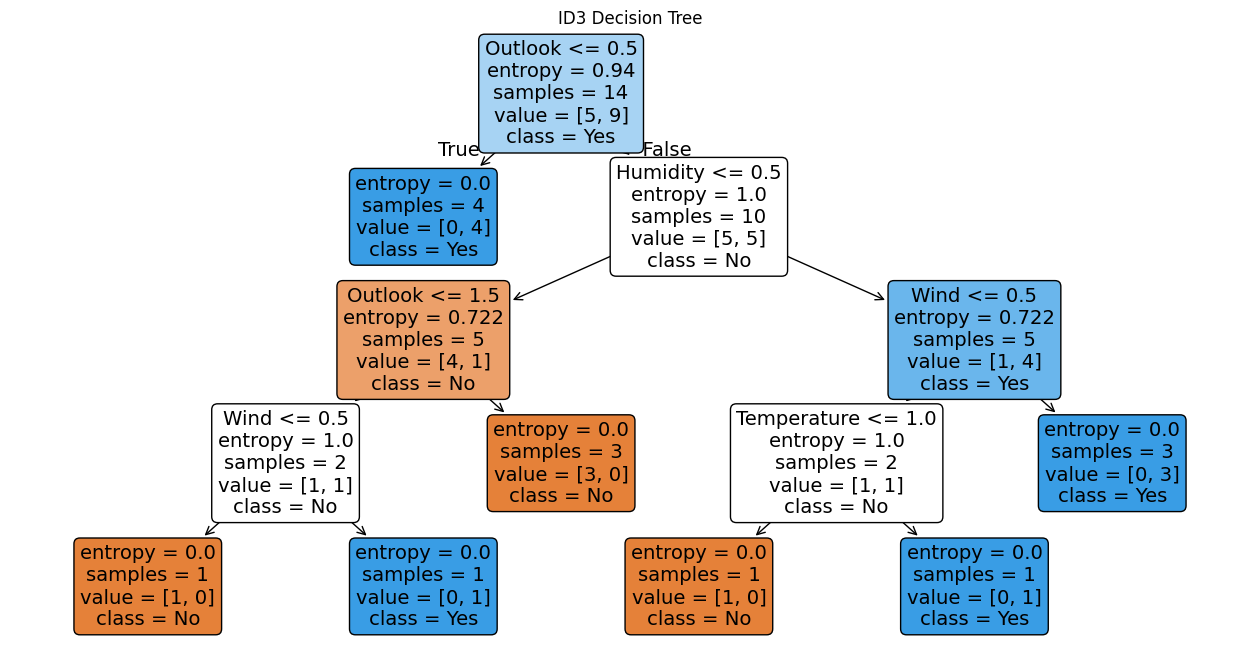


Training Accuracy:
1.0

New Sample:
Outlook = Sunny
Temperature = Cool
Humidity = High
Wind = Strong

Predicted Result:
No


In [ ]:
# ---------------------------------------------------
# 3. ID3 DECISION TREE ALGORITHM
# ---------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score


# ---------------------------------------------------
# STEP 1: Create Dataset
# ---------------------------------------------------

data = {
    'Outlook': [
        'Sunny', 'Sunny', 'Overcast', 'Rain',
        'Rain', 'Rain', 'Overcast', 'Sunny',
        'Sunny', 'Rain', 'Sunny', 'Overcast',
        'Overcast', 'Rain'
    ],

    'Temperature': [
        'Hot', 'Hot', 'Hot', 'Mild',
        'Cool', 'Cool', 'Cool', 'Mild',
        'Cool', 'Mild', 'Mild', 'Mild',
        'Hot', 'Mild'
    ],

    'Humidity': [
        'High', 'High', 'High', 'High',
        'Normal', 'Normal', 'Normal', 'High',
        'Normal', 'Normal', 'Normal', 'High',
        'Normal', 'High'
    ],

    'Wind': [
        'Weak', 'Strong', 'Weak', 'Weak',
        'Weak', 'Strong', 'Strong', 'Weak',
        'Weak', 'Weak', 'Strong', 'Strong',
        'Weak', 'Strong'
    ],

    'PlayTennis': [
        'No', 'No', 'Yes', 'Yes',
        'Yes', 'No', 'Yes', 'No',
        'Yes', 'Yes', 'Yes', 'Yes',
        'Yes', 'No'
    ]
}

df = pd.DataFrame(data)

print("Training Dataset:")
print(df)


# ---------------------------------------------------
# STEP 2: Convert Categorical Data into Numbers
# ---------------------------------------------------

encoders = {}

for column in df.columns:

    encoder = LabelEncoder()

    df[column] = encoder.fit_transform(df[column])

    encoders[column] = encoder


# Features and target
X = df.drop('PlayTennis', axis=1)
y = df['PlayTennis']


# ---------------------------------------------------
# STEP 3: Create ID3 Decision Tree
# ---------------------------------------------------

model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

model.fit(X, y)


# ---------------------------------------------------
# STEP 4: Display Decision Tree
# ---------------------------------------------------

plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['No', 'Yes'],
    filled=True,
    rounded=True
)

plt.title("ID3 Decision Tree")
plt.show()


# ---------------------------------------------------
# STEP 5: Test the Model
# ---------------------------------------------------

y_pred = model.predict(X)

accuracy = accuracy_score(y, y_pred)

print("\nTraining Accuracy:")
print(accuracy)


# ---------------------------------------------------
# STEP 6: Classify a New Sample
# ---------------------------------------------------

# New sample:
# Outlook = Sunny
# Temperature = Cool
# Humidity = High
# Wind = Strong

new_sample = pd.DataFrame({
    'Outlook': [
        encoders['Outlook'].transform(['Sunny'])[0]
    ],

    'Temperature': [
        encoders['Temperature'].transform(['Cool'])[0]
    ],

    'Humidity': [
        encoders['Humidity'].transform(['High'])[0]
    ],

    'Wind': [
        encoders['Wind'].transform(['Strong'])[0]
    ]
})


# Prediction
prediction = model.predict(new_sample)


# Convert prediction back to Yes/No
result = encoders['PlayTennis'].inverse_transform(prediction)


print("\nNew Sample:")
print("Outlook = Sunny")
print("Temperature = Cool")
print("Humidity = High")
print("Wind = Strong")

print("\nPredicted Result:")
print(result[0])

XOR Predictions:
----------------
[0 0] => 0.0277 => Predicted: 0 Actual: 0
[0 1] => 0.9855 => Predicted: 1 Actual: 1
[1 0] => 0.9747 => Predicted: 1 Actual: 1
[1 1] => 0.0207 => Predicted: 0 Actual: 0


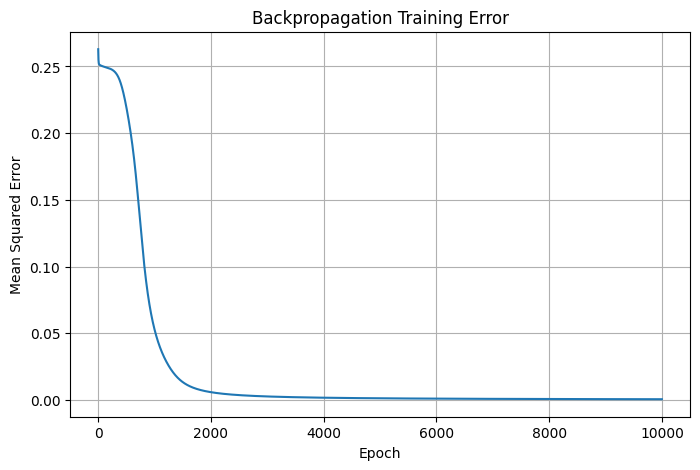

In [ ]:
# ---------------------------------------------------
# 4. ARTIFICIAL NEURAL NETWORK USING BACKPROPAGATION
# ---------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt


# ---------------------------------------------------
# STEP 1: Create XOR Dataset
# ---------------------------------------------------

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([
    [0],
    [1],
    [1],
    [0]
])


# ---------------------------------------------------
# STEP 2: Activation Function
# ---------------------------------------------------

def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def sigmoid_derivative(x):
    return x * (1 - x)


# ---------------------------------------------------
# STEP 3: Initialize Weights
# ---------------------------------------------------

np.random.seed(42)

# Input layer -> Hidden layer
W1 = np.random.uniform(-1, 1, (2, 4))

# Hidden layer -> Output layer
W2 = np.random.uniform(-1, 1, (4, 1))

learning_rate = 0.5

errors = []


# ---------------------------------------------------
# STEP 4: Backpropagation Training
# ---------------------------------------------------

for epoch in range(10000):

    # -------------------------------
    # Forward Propagation
    # -------------------------------

    hidden_input = np.dot(X, W1)

    hidden_output = sigmoid(hidden_input)

    output_input = np.dot(hidden_output, W2)

    output = sigmoid(output_input)


    # -------------------------------
    # Calculate Error
    # -------------------------------

    error = y - output

    mse = np.mean(error ** 2)

    errors.append(mse)


    # -------------------------------
    # Backpropagation
    # -------------------------------

    output_delta = error * sigmoid_derivative(output)

    hidden_error = output_delta.dot(W2.T)

    hidden_delta = hidden_error * sigmoid_derivative(hidden_output)


    # -------------------------------
    # Update Weights
    # -------------------------------

    W2 += hidden_output.T.dot(output_delta) * learning_rate

    W1 += X.T.dot(hidden_delta) * learning_rate


# ---------------------------------------------------
# STEP 5: Display Results
# ---------------------------------------------------

print("XOR Predictions:")
print("----------------")

for i in range(len(X)):

    prediction = output[i][0]

    if prediction >= 0.5:
        result = 1
    else:
        result = 0

    print(
        X[i],
        "=>",
        round(prediction, 4),
        "=> Predicted:",
        result,
        "Actual:",
        y[i][0]
    )


# ---------------------------------------------------
# STEP 6: Plot Training Error
# ---------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(errors)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.title("Backpropagation Training Error")

plt.grid(True)

plt.show()

K value: 5
Accuracy: 0.8

Actual vs Predicted:
--------------------
Actual: versicolor  | Predicted: versicolor
Actual: setosa  | Predicted: setosa
Actual: virginica  | Predicted: virginica
Actual: versicolor  | Predicted: versicolor
Actual: versicolor  | Predicted: versicolor
Actual: setosa  | Predicted: setosa
Actual: versicolor  | Predicted: versicolor
Actual: virginica  | Predicted: virginica
Actual: versicolor  | Predicted: versicolor
Actual: versicolor  | Predicted: virginica
Actual: virginica  | Predicted: virginica
Actual: setosa  | Predicted: setosa
Actual: setosa  | Predicted: setosa
Actual: setosa  | Predicted: setosa
Actual: setosa  | Predicted: setosa
Actual: versicolor  | Predicted: virginica
Actual: virginica  | Predicted: virginica
Actual: versicolor  | Predicted: versicolor
Actual: versicolor  | Predicted: virginica
Actual: virginica  | Predicted: virginica
Actual: setosa  | Predicted: setosa
Actual: virginica  | Predicted: versicolor
Actual: setosa  | Predicted: setos

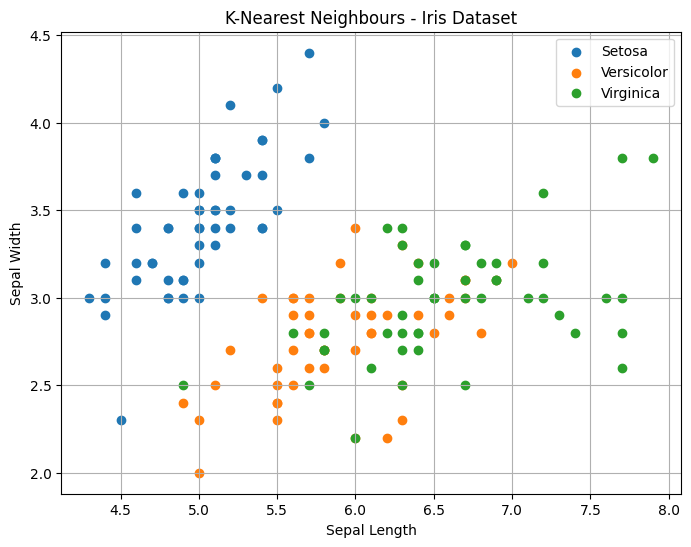

In [ ]:
# ---------------------------------------------------
# 5. K-NEAREST NEIGHBOURS (K-NN)
# ---------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


# ---------------------------------------------------
# STEP 1: Load Iris Dataset
# ---------------------------------------------------

iris = load_iris()

X = iris.data[:, :2]   # First two features
y = iris.target


# ---------------------------------------------------
# STEP 2: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ---------------------------------------------------
# STEP 3: Create K-NN Model
# ---------------------------------------------------

k = 5

model = KNeighborsClassifier(n_neighbors=k)


# ---------------------------------------------------
# STEP 4: Train the Model
# ---------------------------------------------------

model.fit(X_train, y_train)


# ---------------------------------------------------
# STEP 5: Make Predictions
# ---------------------------------------------------

y_pred = model.predict(X_test)


# ---------------------------------------------------
# STEP 6: Calculate Accuracy
# ---------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("K value:", k)

print("Accuracy:",
      accuracy)


# ---------------------------------------------------
# STEP 7: Display Predictions
# ---------------------------------------------------

print("\nActual vs Predicted:")
print("--------------------")

for i in range(len(y_test)):

    actual = iris.target_names[y_test[i]]
    predicted = iris.target_names[y_pred[i]]

    print(
        "Actual:",
        actual,
        " | Predicted:",
        predicted
    )


# ---------------------------------------------------
# STEP 8: Plot Dataset
# ---------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Setosa"
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Versicolor"
)

plt.scatter(
    X[y == 2, 0],
    X[y == 2, 1],
    label="Virginica"
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")

plt.title("K-Nearest Neighbours - Iris Dataset")

plt.legend()

plt.grid(True)

plt.show()

Naive Bayes Classification
--------------------------

Accuracy:
1.0

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


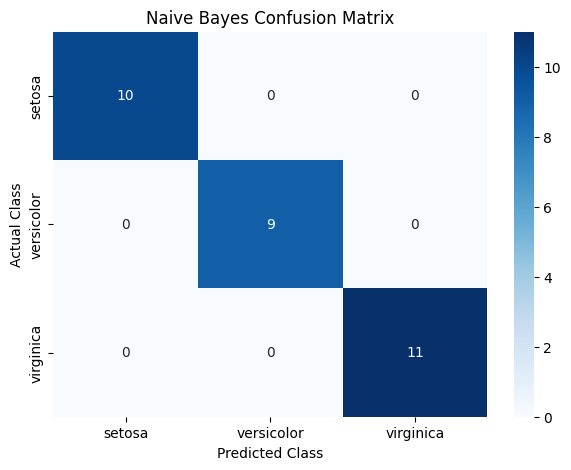

In [ ]:
# ---------------------------------------------------
# 6. NAIVE BAYES CLASSIFICATION
# ---------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix


# ---------------------------------------------------
# STEP 1: Load Iris Dataset
# ---------------------------------------------------

iris = load_iris()

X = iris.data
y = iris.target


# ---------------------------------------------------
# STEP 2: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ---------------------------------------------------
# STEP 3: Create Naive Bayes Model
# ---------------------------------------------------

model = GaussianNB()


# ---------------------------------------------------
# STEP 4: Train Model
# ---------------------------------------------------

model.fit(X_train, y_train)


# ---------------------------------------------------
# STEP 5: Make Predictions
# ---------------------------------------------------

y_pred = model.predict(X_test)


# ---------------------------------------------------
# STEP 6: Calculate Accuracy
# ---------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("Naive Bayes Classification")
print("--------------------------")

print("\nAccuracy:")
print(accuracy)


# ---------------------------------------------------
# STEP 7: Confusion Matrix
# ---------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


# ---------------------------------------------------
# STEP 8: Display Confusion Matrix as Graph
# ---------------------------------------------------

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("Naive Bayes Confusion Matrix")

plt.show()

Logistic Regression
-------------------

Accuracy:
0.9

Confusion Matrix:
[[10  0  0]
 [ 0  7  2]
 [ 0  1 10]]


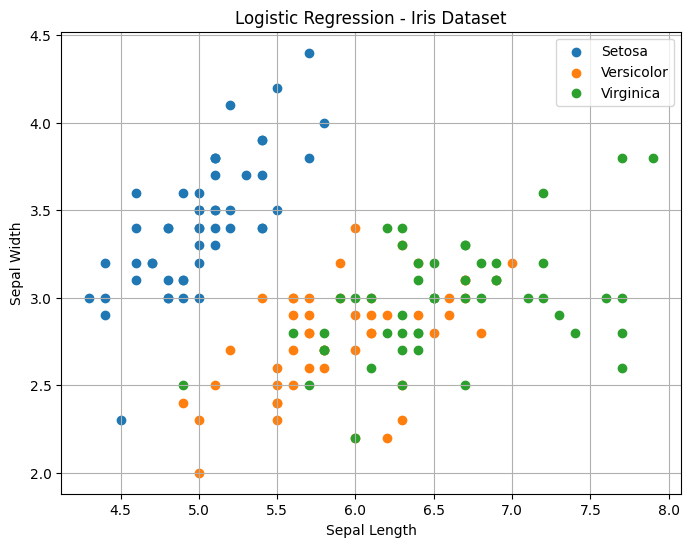

In [ ]:
# ---------------------------------------------------
# 7. LOGISTIC REGRESSION
# ---------------------------------------------------

import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix


# ---------------------------------------------------
# STEP 1: Load Iris Dataset
# ---------------------------------------------------

iris = load_iris()

# Use first two features for easy visualization
X = iris.data[:, :2]

y = iris.target


# ---------------------------------------------------
# STEP 2: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ---------------------------------------------------
# STEP 3: Create Logistic Regression Model
# ---------------------------------------------------

model = LogisticRegression(
    max_iter=200
)


# ---------------------------------------------------
# STEP 4: Train the Model
# ---------------------------------------------------

model.fit(X_train, y_train)


# ---------------------------------------------------
# STEP 5: Make Predictions
# ---------------------------------------------------

y_pred = model.predict(X_test)


# ---------------------------------------------------
# STEP 6: Calculate Accuracy
# ---------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression")
print("-------------------")

print("\nAccuracy:")
print(accuracy)


# ---------------------------------------------------
# STEP 7: Display Confusion Matrix
# ---------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


# ---------------------------------------------------
# STEP 8: Plot Dataset
# ---------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Setosa"
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Versicolor"
)

plt.scatter(
    X[y == 2, 0],
    X[y == 2, 1],
    label="Virginica"
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")

plt.title("Logistic Regression - Iris Dataset")

plt.legend()

plt.grid(True)

plt.show()

Linear Regression
------------------

Actual Values:
[200  70]

Predicted Values:
[200.  70.]

Mean Squared Error:
4.0389678347315804e-28

R2 Score:
1.0

For a house of 1500 sq.ft:
Predicted Price = 150.0 lakhs


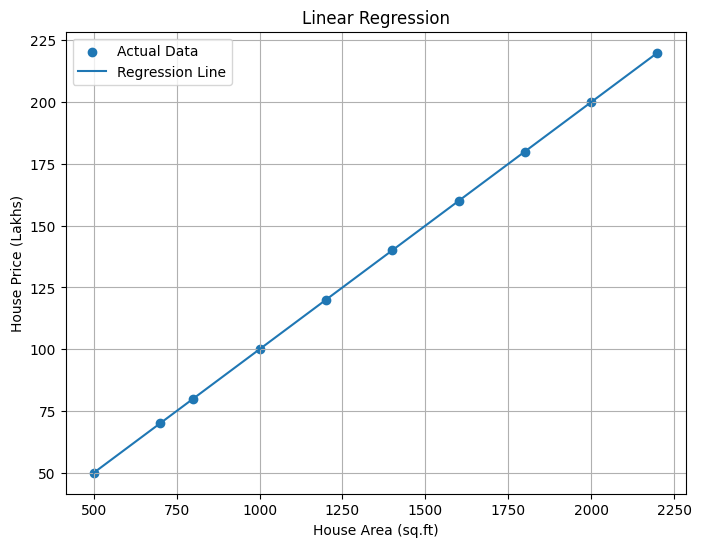

In [ ]:
# ---------------------------------------------------
# 8. LINEAR REGRESSION
# ---------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


# ---------------------------------------------------
# STEP 1: Create Dataset
# ---------------------------------------------------

# House area in square feet
X = np.array([
    [500],
    [700],
    [800],
    [1000],
    [1200],
    [1400],
    [1600],
    [1800],
    [2000],
    [2200]
])

# House price in lakhs
y = np.array([
    50,
    70,
    80,
    100,
    120,
    140,
    160,
    180,
    200,
    220
])


# ---------------------------------------------------
# STEP 2: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ---------------------------------------------------
# STEP 3: Create Linear Regression Model
# ---------------------------------------------------

model = LinearRegression()


# ---------------------------------------------------
# STEP 4: Train the Model
# ---------------------------------------------------

model.fit(X_train, y_train)


# ---------------------------------------------------
# STEP 5: Make Predictions
# ---------------------------------------------------

y_pred = model.predict(X_test)


# ---------------------------------------------------
# STEP 6: Display Results
# ---------------------------------------------------

print("Linear Regression")
print("------------------")

print("\nActual Values:")
print(y_test)

print("\nPredicted Values:")
print(y_pred)


# ---------------------------------------------------
# STEP 7: Calculate Performance
# ---------------------------------------------------

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("\nMean Squared Error:")
print(mse)

print("\nR2 Score:")
print(r2)


# ---------------------------------------------------
# STEP 8: Predict Price for New House
# ---------------------------------------------------

new_house = np.array([[1500]])

predicted_price = model.predict(new_house)

print("\nFor a house of 1500 sq.ft:")
print("Predicted Price =",
      round(predicted_price[0], 2),
      "lakhs")


# ---------------------------------------------------
# STEP 9: Plot Regression Line
# ---------------------------------------------------

plt.figure(figsize=(8, 6))

# Actual data
plt.scatter(
    X,
    y,
    label="Actual Data"
)

# Regression line
plt.plot(
    X,
    model.predict(X),
    label="Regression Line"
)

plt.xlabel("House Area (sq.ft)")
plt.ylabel("House Price (Lakhs)")

plt.title("Linear Regression")

plt.legend()

plt.grid(True)

plt.show()

LINEAR VS POLYNOMIAL REGRESSION
--------------------------------

Linear Regression:
MSE = 52.8
R2 Score = 0.9498

Polynomial Regression:
Degree = 2
MSE = 0.0
R2 Score = 1.0

Polynomial Regression performs better.


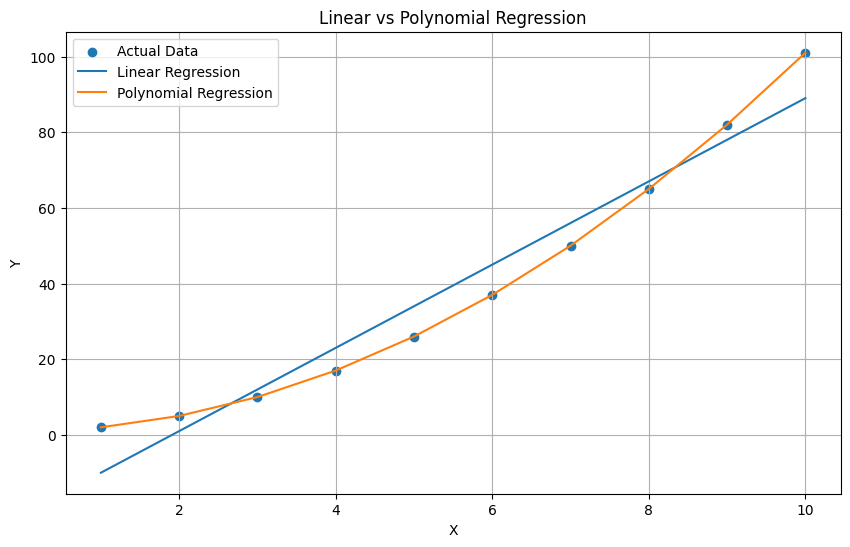

In [ ]:
# ---------------------------------------------------
# 9. LINEAR vs POLYNOMIAL REGRESSION
# ---------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score


# ---------------------------------------------------
# STEP 1: Create Dataset
# ---------------------------------------------------

X = np.array([
    [1],
    [2],
    [3],
    [4],
    [5],
    [6],
    [7],
    [8],
    [9],
    [10]
])

y = np.array([
    2,
    5,
    10,
    17,
    26,
    37,
    50,
    65,
    82,
    101
])


# ---------------------------------------------------
# STEP 2: Linear Regression
# ---------------------------------------------------

linear_model = LinearRegression()

linear_model.fit(X, y)

linear_pred = linear_model.predict(X)


# ---------------------------------------------------
# STEP 3: Polynomial Regression
# ---------------------------------------------------

# Degree of polynomial
degree = 2

poly = PolynomialFeatures(degree=degree)

X_poly = poly.fit_transform(X)

poly_model = LinearRegression()

poly_model.fit(X_poly, y)

poly_pred = poly_model.predict(X_poly)


# ---------------------------------------------------
# STEP 4: Calculate Errors
# ---------------------------------------------------

linear_mse = mean_squared_error(y, linear_pred)

poly_mse = mean_squared_error(y, poly_pred)

linear_r2 = r2_score(y, linear_pred)

poly_r2 = r2_score(y, poly_pred)


# ---------------------------------------------------
# STEP 5: Display Results
# ---------------------------------------------------

print("LINEAR VS POLYNOMIAL REGRESSION")
print("--------------------------------")

print("\nLinear Regression:")
print("MSE =", round(linear_mse, 4))
print("R2 Score =", round(linear_r2, 4))

print("\nPolynomial Regression:")
print("Degree =", degree)
print("MSE =", round(poly_mse, 4))
print("R2 Score =", round(poly_r2, 4))


# ---------------------------------------------------
# STEP 6: Compare Models
# ---------------------------------------------------

if poly_mse < linear_mse:
    print("\nPolynomial Regression performs better.")

else:
    print("\nLinear Regression performs better.")


# ---------------------------------------------------
# STEP 7: Plot Comparison
# ---------------------------------------------------

plt.figure(figsize=(10, 6))

# Actual data
plt.scatter(
    X,
    y,
    label="Actual Data"
)

# Linear regression line
plt.plot(
    X,
    linear_pred,
    label="Linear Regression"
)

# Polynomial regression curve
plt.plot(
    X,
    poly_pred,
    label="Polynomial Regression"
)

plt.xlabel("X")
plt.ylabel("Y")

plt.title("Linear vs Polynomial Regression")

plt.legend()

plt.grid(True)

plt.show()

Expectation-Maximization Algorithm
-----------------------------------

Cluster Means:
[1.94807669 7.01784341]

Number of Data Points in Each Cluster:
Cluster 1 : 100 data points
Cluster 2 : 100 data points


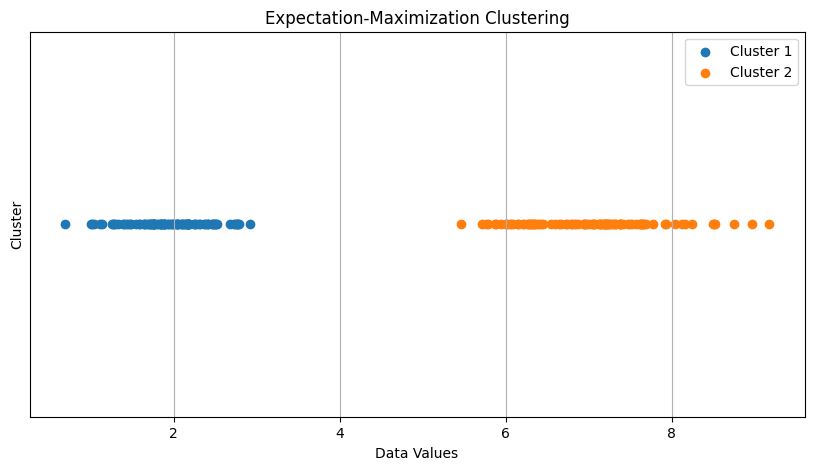

In [ ]:
# ---------------------------------------------------
# 10. EXPECTATION-MAXIMIZATION (EM) ALGORITHM
# ---------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

from sklearn.mixture import GaussianMixture


# ---------------------------------------------------
# STEP 1: Create Dataset
# ---------------------------------------------------

np.random.seed(42)

# First group
data1 = np.random.normal(
    loc=2,
    scale=0.5,
    size=100
)

# Second group
data2 = np.random.normal(
    loc=7,
    scale=0.8,
    size=100
)

# Combine both groups
X = np.concatenate([data1, data2])

# Convert to 2D
X = X.reshape(-1, 1)


# ---------------------------------------------------
# STEP 2: Create EM Model
# ---------------------------------------------------

model = GaussianMixture(
    n_components=2,
    random_state=42
)


# ---------------------------------------------------
# STEP 3: Apply EM Algorithm
# ---------------------------------------------------

model.fit(X)


# ---------------------------------------------------
# STEP 4: Predict Clusters
# ---------------------------------------------------

labels = model.predict(X)


# ---------------------------------------------------
# STEP 5: Display Cluster Means
# ---------------------------------------------------

print("Expectation-Maximization Algorithm")
print("-----------------------------------")

print("\nCluster Means:")

print(model.means_.flatten())


# ---------------------------------------------------
# STEP 6: Display Cluster Information
# ---------------------------------------------------

print("\nNumber of Data Points in Each Cluster:")

for i in range(2):

    count = np.sum(labels == i)

    print(
        "Cluster",
        i + 1,
        ":",
        count,
        "data points"
    )


# ---------------------------------------------------
# STEP 7: Plot Clusters
# ---------------------------------------------------

plt.figure(figsize=(10, 5))

plt.scatter(
    X[labels == 0],
    np.zeros(np.sum(labels == 0)),
    label="Cluster 1"
)

plt.scatter(
    X[labels == 1],
    np.zeros(np.sum(labels == 1)),
    label="Cluster 2"
)

plt.xlabel("Data Values")

plt.ylabel("Cluster")

plt.title("Expectation-Maximization Clustering")

plt.yticks([])

plt.legend()

plt.grid(True)

plt.show()

Credit Score Dataset:
   Income   Debt  Payment_History  Credit_Utilization Credit_Score
0   50000  10000               90                  20         Good
1   60000  15000               85                  25         Good
2   25000  20000               40                  85         Poor
3   80000  10000               95                  15         Good
4   30000  18000               50                  75         Poor
5   90000  12000               98                  10         Good
6   45000  22000               60                  70         Poor
7   75000  15000               88                  30         Good
8   28000  25000               35                  90         Poor
9   85000  10000               96                  12         Good

Actual Credit Scores:
['Good', 'Good', 'Poor', 'Poor', 'Good']

Predicted Credit Scores:
['Good', 'Good', 'Good', 'Poor', 'Good']

Model Accuracy:
80.0 %

Confusion Matrix:
[[1 1]
 [0 3]]


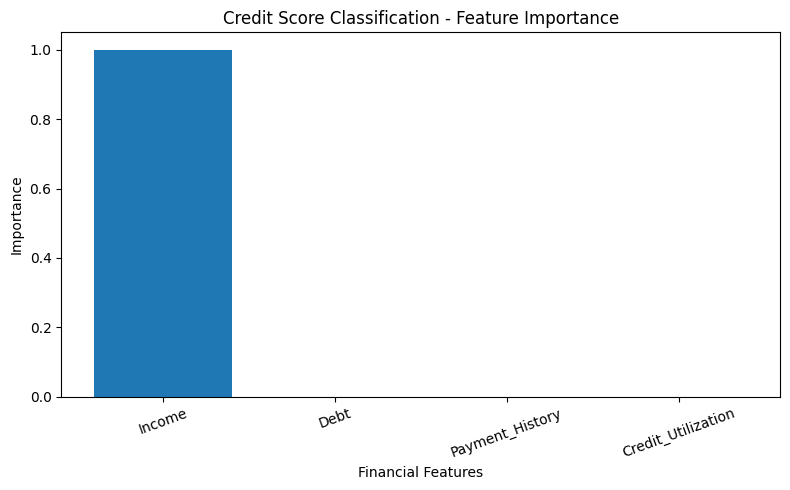

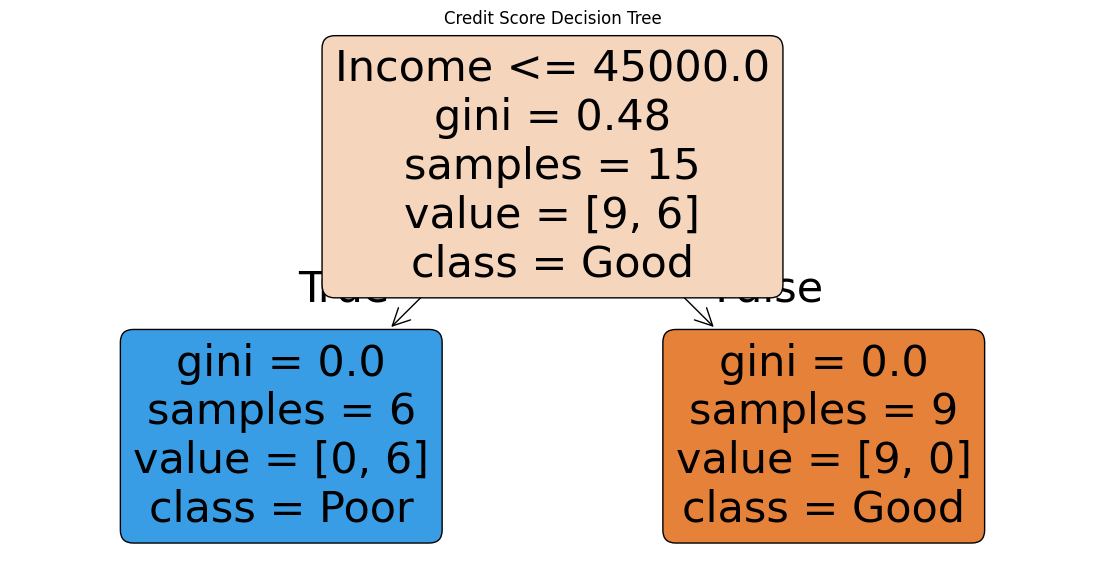


New Person's Financial Details:
   Income   Debt  Payment_History  Credit_Utilization
0   70000  12000               95                  15

Predicted Credit Score:
Good


In [ ]:
# EXP-11
# ---------------------------------------------------
# 11. CREDIT SCORE CLASSIFICATION
# ---------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix


# ---------------------------------------------------
# STEP 1: Create Dataset
# ---------------------------------------------------

data = {
    'Income': [
        50000, 60000, 25000, 80000, 30000,
        90000, 45000, 75000, 28000, 85000,
        40000, 70000, 35000, 95000, 55000,
        65000, 20000, 100000, 48000, 78000
    ],

    'Debt': [
        10000, 15000, 20000, 10000, 18000,
        12000, 22000, 15000, 25000, 10000,
        18000, 12000, 20000, 8000, 14000,
        16000, 22000, 9000, 17000, 11000
    ],

    'Payment_History': [
        90, 85, 40, 95, 50,
        98, 60, 88, 35, 96,
        55, 92, 45, 99, 80,
        75, 30, 100, 65, 94
    ],

    'Credit_Utilization': [
        20, 25, 85, 15, 75,
        10, 70, 30, 90, 12,
        65, 18, 80, 8, 35,
        40, 95, 5, 60, 22
    ],

    'Credit_Score': [
        'Good', 'Good', 'Poor', 'Good', 'Poor',
        'Good', 'Poor', 'Good', 'Poor', 'Good',
        'Poor', 'Good', 'Poor', 'Good', 'Good',
        'Good', 'Poor', 'Good', 'Poor', 'Good'
    ]
}

df = pd.DataFrame(data)

print("Credit Score Dataset:")
print(df.head(10))


# ---------------------------------------------------
# STEP 2: Separate Features and Target
# ---------------------------------------------------

X = df.drop('Credit_Score', axis=1)
y = df['Credit_Score']


# ---------------------------------------------------
# STEP 3: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


# ---------------------------------------------------
# STEP 4: Train Decision Tree Model
# ---------------------------------------------------

model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)


# ---------------------------------------------------
# STEP 5: Predict Credit Scores
# ---------------------------------------------------

y_pred = model.predict(X_test)

print("\nActual Credit Scores:")
print(list(y_test))

print("\nPredicted Credit Scores:")
print(list(y_pred))


# ---------------------------------------------------
# STEP 6: Calculate Accuracy
# ---------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:")
print(round(accuracy * 100, 2), "%")


# ---------------------------------------------------
# STEP 7: Display Confusion Matrix
# ---------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Poor', 'Good']
)

print("\nConfusion Matrix:")
print(cm)


# ---------------------------------------------------
# STEP 8: Plot Feature Importance
# ---------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    X.columns,
    model.feature_importances_
)

plt.xlabel("Financial Features")
plt.ylabel("Importance")

plt.title("Credit Score Classification - Feature Importance")

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()


# ---------------------------------------------------
# STEP 9: Visualize Decision Tree
# ---------------------------------------------------

plt.figure(figsize=(14, 7))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True
)

plt.title("Credit Score Decision Tree")

plt.show()


# ---------------------------------------------------
# STEP 10: Predict for a New Person
# ---------------------------------------------------

new_person = pd.DataFrame({
    'Income': [70000],
    'Debt': [12000],
    'Payment_History': [95],
    'Credit_Utilization': [15]
})

prediction = model.predict(new_person)

print("\nNew Person's Financial Details:")
print(new_person)

print("\nPredicted Credit Score:")
print(prediction[0])

Iris Flower Classification Using KNN
-------------------------------------

Dataset Shape: (150, 4)
Flower Classes: ['setosa' 'versicolor' 'virginica']

Model Accuracy:
100.0 %

Actual vs Predicted:
--------------------
Actual: setosa | Predicted: setosa
Actual: virginica | Predicted: virginica
Actual: versicolor | Predicted: versicolor
Actual: versicolor | Predicted: versicolor
Actual: setosa | Predicted: setosa
Actual: versicolor | Predicted: versicolor
Actual: setosa | Predicted: setosa
Actual: setosa | Predicted: setosa
Actual: virginica | Predicted: virginica
Actual: versicolor | Predicted: versicolor

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


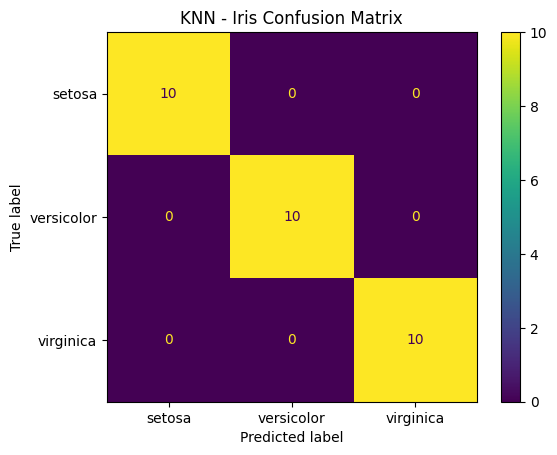

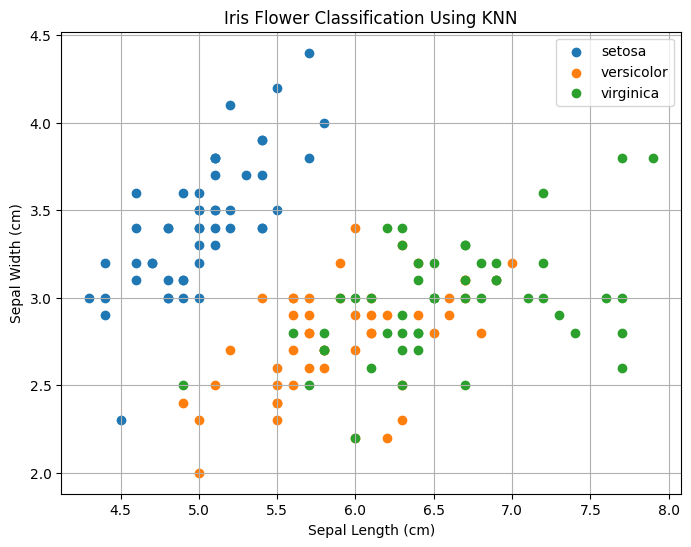


New Flower Measurements:
Sepal Length = 5.1 cm
Sepal Width  = 3.5 cm
Petal Length = 1.4 cm
Petal Width  = 0.2 cm

Predicted Flower Species:
setosa


In [ ]:
# ---------------------------------------------------
# 12. IRIS FLOWER CLASSIFICATION USING KNN
# ---------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


# ---------------------------------------------------
# STEP 1: Load Iris Dataset
# ---------------------------------------------------

iris = load_iris()

X = iris.data
y = iris.target

print("Iris Flower Classification Using KNN")
print("-------------------------------------")

print("\nDataset Shape:", X.shape)
print("Flower Classes:", iris.target_names)


# ---------------------------------------------------
# STEP 2: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ---------------------------------------------------
# STEP 3: Create KNN Model
# ---------------------------------------------------

model = KNeighborsClassifier(n_neighbors=5)


# ---------------------------------------------------
# STEP 4: Train the Model
# ---------------------------------------------------

model.fit(X_train, y_train)


# ---------------------------------------------------
# STEP 5: Predict Flower Species
# ---------------------------------------------------

y_pred = model.predict(X_test)


# ---------------------------------------------------
# STEP 6: Calculate Accuracy
# ---------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:")
print(round(accuracy * 100, 2), "%")


# ---------------------------------------------------
# STEP 7: Display Predictions
# ---------------------------------------------------

print("\nActual vs Predicted:")
print("--------------------")

for i in range(10):
    actual = iris.target_names[y_test[i]]
    predicted = iris.target_names[y_pred[i]]

    print("Actual:", actual, "| Predicted:", predicted)


# ---------------------------------------------------
# STEP 8: Display Confusion Matrix
# ---------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot()

plt.title("KNN - Iris Confusion Matrix")
plt.show()


# ---------------------------------------------------
# STEP 9: Visualize Iris Dataset
# ---------------------------------------------------

plt.figure(figsize=(8, 6))

for i, name in enumerate(iris.target_names):
    plt.scatter(
        X[y == i, 0],
        X[y == i, 1],
        label=name
    )

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")

plt.title("Iris Flower Classification Using KNN")

plt.legend()
plt.grid(True)
plt.show()


# ---------------------------------------------------
# STEP 10: Classify a New Flower
# ---------------------------------------------------

new_flower = np.array([[5.1, 3.5, 1.4, 0.2]])

prediction = model.predict(new_flower)

print("\nNew Flower Measurements:")
print("Sepal Length = 5.1 cm")
print("Sepal Width  = 3.5 cm")
print("Petal Length = 1.4 cm")
print("Petal Width  = 0.2 cm")

print("\nPredicted Flower Species:")
print(iris.target_names[prediction[0]])

Car Price Dataset:
   Age  Mileage  Horsepower  Price
0    1    10000         120   12.0
1    2    20000         110   10.0
2    3    30000         100    8.0
3    4    40000          95    7.0
4    5    50000          90    6.0

Actual Car Prices:
[12.   3.   4.8 10. ]

Predicted Car Prices:
[11.72  2.6   5.39  9.86]

Model Evaluation:
Mean Absolute Error: 0.35
Mean Squared Error: 0.15
R2 Score: 0.99

New Car Details:
   Age  Mileage  Horsepower
0    2    20000         120

Predicted Car Price:
11.0 Lakhs


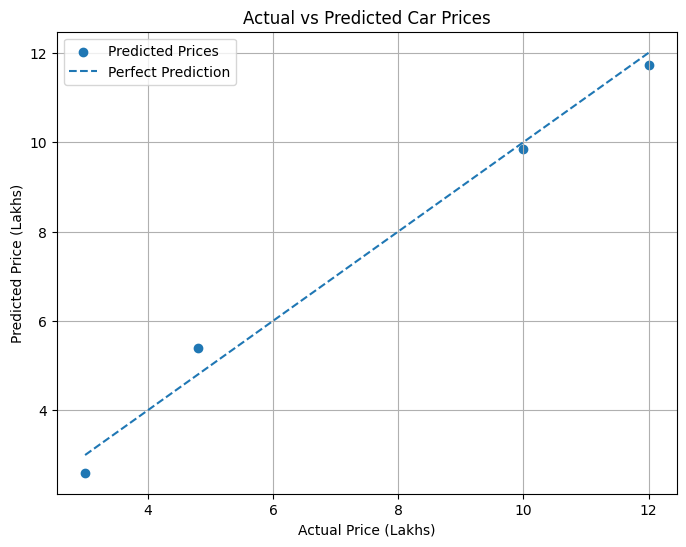

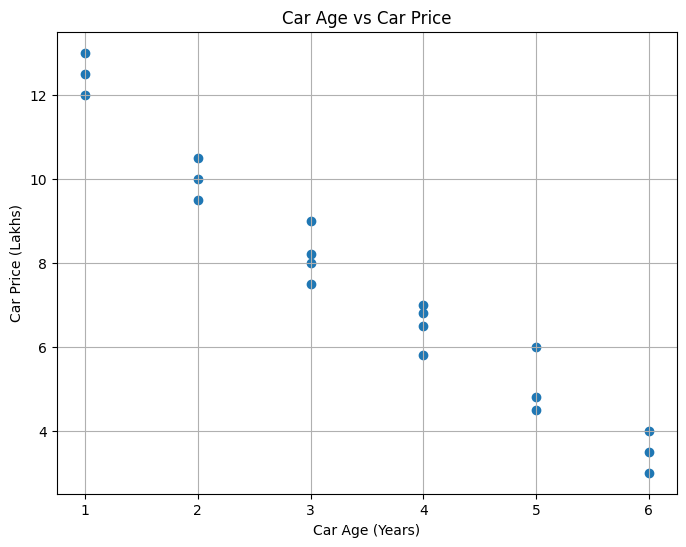

In [ ]:
# ---------------------------------------------------
# 13. CAR PRICE PREDICTION USING LINEAR REGRESSION
# ---------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ---------------------------------------------------
# STEP 1: Create Dataset
# ---------------------------------------------------

data = {
    'Age': [1, 2, 3, 4, 5, 6, 2, 3, 4, 5,
            1, 6, 2, 4, 3, 5, 1, 6, 3, 4],

    'Mileage': [10000, 20000, 30000, 40000, 50000,
                60000, 25000, 35000, 45000, 55000,
                12000, 65000, 22000, 42000, 32000,
                52000, 15000, 70000, 28000, 48000],

    'Horsepower': [120, 110, 100, 95, 90, 85, 115, 105,
                   100, 90, 125, 80, 118, 98, 108, 92,
                   130, 82, 112, 96],

    'Price': [12, 10, 8, 7, 6, 4, 9.5, 7.5, 6.5, 4.5,
              12.5, 3.5, 10.5, 6.8, 8.2, 4.8, 13, 3,
              9, 5.8]
}

df = pd.DataFrame(data)

print("Car Price Dataset:")
print(df.head())


# ---------------------------------------------------
# STEP 2: Separate Features and Target
# ---------------------------------------------------

X = df[['Age', 'Mileage', 'Horsepower']]

y = df['Price']


# ---------------------------------------------------
# STEP 3: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ---------------------------------------------------
# STEP 4: Train Linear Regression Model
# ---------------------------------------------------

model = LinearRegression()

model.fit(X_train, y_train)


# ---------------------------------------------------
# STEP 5: Predict Car Prices
# ---------------------------------------------------

y_pred = model.predict(X_test)

print("\nActual Car Prices:")
print(y_test.values)

print("\nPredicted Car Prices:")
print(np.round(y_pred, 2))


# ---------------------------------------------------
# STEP 6: Evaluate Model
# ---------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 2))


# ---------------------------------------------------
# STEP 7: Predict Price of a New Car
# ---------------------------------------------------

new_car = pd.DataFrame({
    'Age': [2],
    'Mileage': [20000],
    'Horsepower': [120]
})

predicted_price = model.predict(new_car)

print("\nNew Car Details:")
print(new_car)

print("\nPredicted Car Price:")
print(round(predicted_price[0], 2), "Lakhs")


# ---------------------------------------------------
# STEP 8: Plot Actual vs Predicted Prices
# ---------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    label="Predicted Prices"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--',
    label="Perfect Prediction"
)

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")

plt.title("Actual vs Predicted Car Prices")

plt.legend()
plt.grid(True)
plt.show()


# ---------------------------------------------------
# STEP 9: Plot Car Age vs Price
# ---------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    df['Age'],
    df['Price']
)

plt.xlabel("Car Age (Years)")
plt.ylabel("Car Price (Lakhs)")

plt.title("Car Age vs Car Price")

plt.grid(True)
plt.show()

Car Price Dataset:
   Age  Mileage  Horsepower  Price
0    1    10000         120   12.0
1    2    20000         110   10.0
2    3    30000         100    8.0
3    4    40000          95    7.0
4    5    50000          90    6.0

Actual Car Prices:
[12.   3.   4.8 10. ]

Predicted Car Prices:
[11.72  2.6   5.39  9.86]

Model Evaluation:
Mean Absolute Error: 0.35
Mean Squared Error: 0.15
R2 Score: 0.99

New Car Details:
   Age  Mileage  Horsepower
0    2    20000         120

Predicted Car Price:
11.0 Lakhs


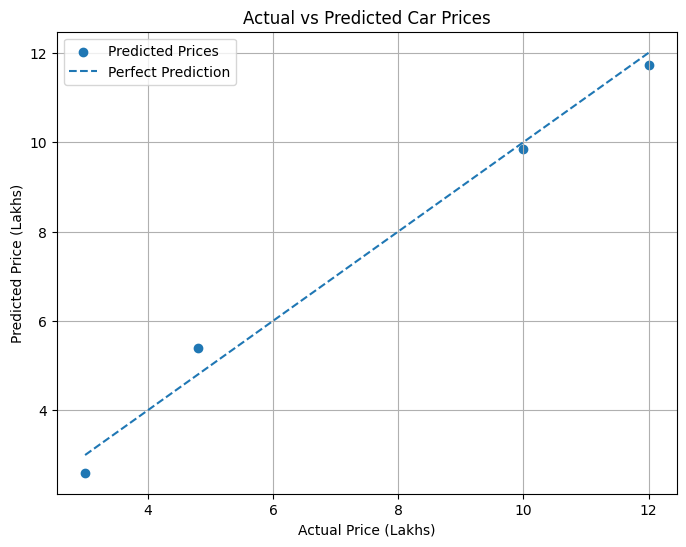

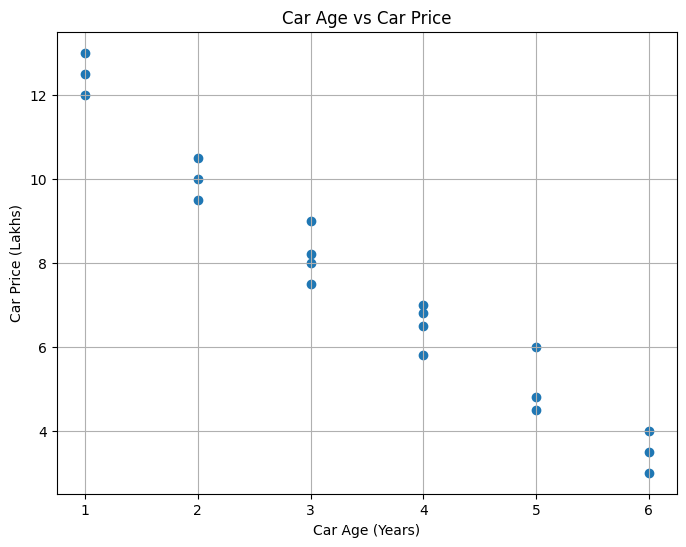

In [ ]:
# EXP-13
# ---------------------------------------------------
# 13. CAR PRICE PREDICTION USING LINEAR REGRESSION
# ---------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ---------------------------------------------------
# STEP 1: Create Dataset
# ---------------------------------------------------

data = {
    'Age': [1, 2, 3, 4, 5, 6, 2, 3, 4, 5,
            1, 6, 2, 4, 3, 5, 1, 6, 3, 4],

    'Mileage': [10000, 20000, 30000, 40000, 50000,
                60000, 25000, 35000, 45000, 55000,
                12000, 65000, 22000, 42000, 32000,
                52000, 15000, 70000, 28000, 48000],

    'Horsepower': [120, 110, 100, 95, 90, 85, 115, 105,
                   100, 90, 125, 80, 118, 98, 108, 92,
                   130, 82, 112, 96],

    'Price': [12, 10, 8, 7, 6, 4, 9.5, 7.5, 6.5, 4.5,
              12.5, 3.5, 10.5, 6.8, 8.2, 4.8, 13, 3,
              9, 5.8]
}

df = pd.DataFrame(data)

print("Car Price Dataset:")
print(df.head())


# ---------------------------------------------------
# STEP 2: Separate Features and Target
# ---------------------------------------------------

X = df[['Age', 'Mileage', 'Horsepower']]

y = df['Price']


# ---------------------------------------------------
# STEP 3: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ---------------------------------------------------
# STEP 4: Train Linear Regression Model
# ---------------------------------------------------

model = LinearRegression()

model.fit(X_train, y_train)


# ---------------------------------------------------
# STEP 5: Predict Car Prices
# ---------------------------------------------------

y_pred = model.predict(X_test)

print("\nActual Car Prices:")
print(y_test.values)

print("\nPredicted Car Prices:")
print(np.round(y_pred, 2))


# ---------------------------------------------------
# STEP 6: Evaluate Model
# ---------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 2))


# ---------------------------------------------------
# STEP 7: Predict Price of a New Car
# ---------------------------------------------------

new_car = pd.DataFrame({
    'Age': [2],
    'Mileage': [20000],
    'Horsepower': [120]
})

predicted_price = model.predict(new_car)

print("\nNew Car Details:")
print(new_car)

print("\nPredicted Car Price:")
print(round(predicted_price[0], 2), "Lakhs")


# ---------------------------------------------------
# STEP 8: Plot Actual vs Predicted Prices
# ---------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    label="Predicted Prices"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--',
    label="Perfect Prediction"
)

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")

plt.title("Actual vs Predicted Car Prices")

plt.legend()
plt.grid(True)
plt.show()


# ---------------------------------------------------
# STEP 9: Plot Car Age vs Price
# ---------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    df['Age'],
    df['Price']
)

plt.xlabel("Car Age (Years)")
plt.ylabel("Car Price (Lakhs)")

plt.title("Car Age vs Car Price")

plt.grid(True)
plt.show()

House Price Dataset:
   Area  Bedrooms  Age  Price
0   800         2   10     25
1  1000         2    8     30
2  1200         3    5     40
3  1500         3    6     50
4  1800         3    4     60
5  2000         4    3     70
6  2200         4    2     80
7  2500         4    1     95
8   900         2   12     27
9  1400         3    7     45

Actual House Prices:
[ 25 100  62  30]

Predicted House Prices:
[18.22 99.33 65.57 25.98]

Model Evaluation:
Mean Absolute Error: 3.76
Mean Squared Error: 18.84
R2 Score: 0.98

New House Details:
   Area  Bedrooms  Age
0  1800         3    5

Predicted House Price:
61.69 Lakhs


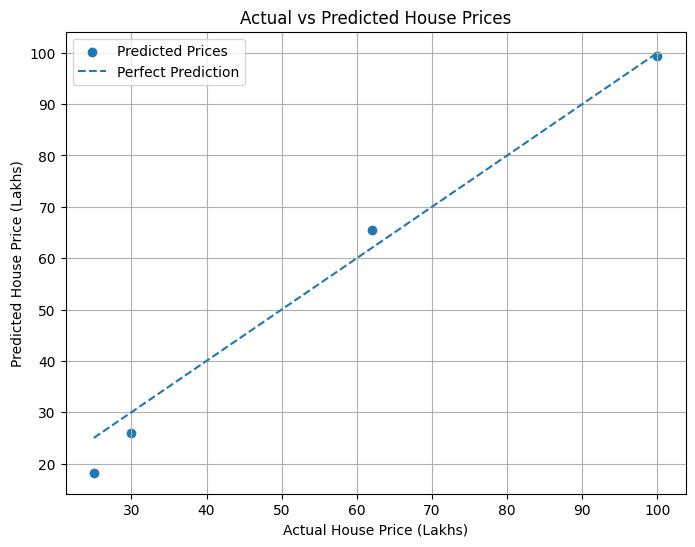

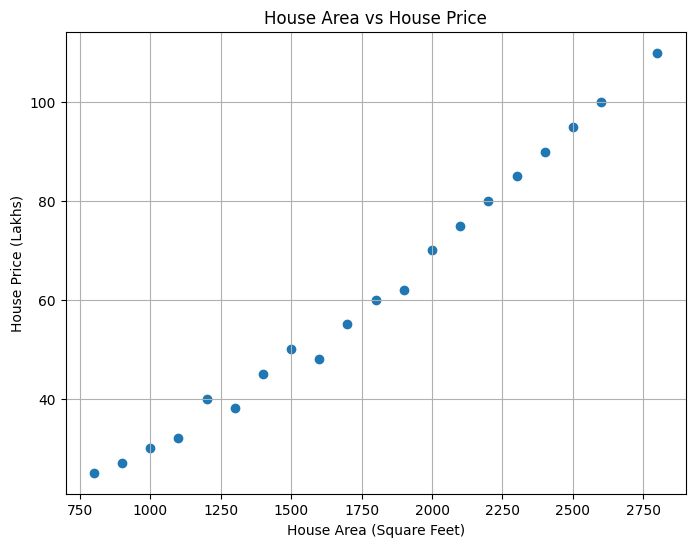

In [ ]:
# ---------------------------------------------------
# 14. HOUSE PRICE PREDICTION
# ---------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ---------------------------------------------------
# STEP 1: Create Dataset
# ---------------------------------------------------

data = {
    'Area': [
        800, 1000, 1200, 1500, 1800,
        2000, 2200, 2500, 900, 1400,
        1700, 2100, 2400, 1100, 1600,
        1900, 2300, 2600, 1300, 2800
    ],

    'Bedrooms': [
        2, 2, 3, 3, 3,
        4, 4, 4, 2, 3,
        3, 4, 4, 2, 3,
        3, 4, 5, 3, 5
    ],

    'Age': [
        10, 8, 5, 6, 4,
        3, 2, 1, 12, 7,
        5, 3, 2, 9, 6,
        4, 3, 1, 8, 1
    ],

    'Price': [
        25, 30, 40, 50, 60,
        70, 80, 95, 27, 45,
        55, 75, 90, 32, 48,
        62, 85, 100, 38, 110
    ]
}

df = pd.DataFrame(data)

print("House Price Dataset:")
print(df.head(10))


# ---------------------------------------------------
# STEP 2: Separate Features and Target
# ---------------------------------------------------

X = df[['Area', 'Bedrooms', 'Age']]

y = df['Price']


# ---------------------------------------------------
# STEP 3: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ---------------------------------------------------
# STEP 4: Train Linear Regression Model
# ---------------------------------------------------

model = LinearRegression()

model.fit(X_train, y_train)


# ---------------------------------------------------
# STEP 5: Predict House Prices
# ---------------------------------------------------

y_pred = model.predict(X_test)

print("\nActual House Prices:")
print(y_test.values)

print("\nPredicted House Prices:")
print(np.round(y_pred, 2))


# ---------------------------------------------------
# STEP 6: Evaluate Model
# ---------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 2))


# ---------------------------------------------------
# STEP 7: Predict Price of a New House
# ---------------------------------------------------

new_house = pd.DataFrame({
    'Area': [1800],
    'Bedrooms': [3],
    'Age': [5]
})

predicted_price = model.predict(new_house)

print("\nNew House Details:")
print(new_house)

print("\nPredicted House Price:")
print(round(predicted_price[0], 2), "Lakhs")


# ---------------------------------------------------
# STEP 8: Plot Actual vs Predicted Prices
# ---------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, label="Predicted Prices")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--',
    label="Perfect Prediction"
)

plt.xlabel("Actual House Price (Lakhs)")
plt.ylabel("Predicted House Price (Lakhs)")

plt.title("Actual vs Predicted House Prices")

plt.legend()
plt.grid(True)
plt.show()


# ---------------------------------------------------
# STEP 9: Plot Area vs House Price
# ---------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(df['Area'], df['Price'])

plt.xlabel("House Area (Square Feet)")
plt.ylabel("House Price (Lakhs)")

plt.title("House Area vs House Price")

plt.grid(True)
plt.show()

Iris Flower Classification Using Naive Bayes
---------------------------------------------

Dataset Shape: (150, 4)
Flower Classes: ['setosa' 'versicolor' 'virginica']

Model Accuracy:
96.67 %

Actual vs Predicted:
--------------------
Actual: setosa | Predicted: setosa
Actual: virginica | Predicted: virginica
Actual: versicolor | Predicted: versicolor
Actual: versicolor | Predicted: versicolor
Actual: setosa | Predicted: setosa
Actual: versicolor | Predicted: versicolor
Actual: setosa | Predicted: setosa
Actual: setosa | Predicted: setosa
Actual: virginica | Predicted: virginica
Actual: versicolor | Predicted: versicolor

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


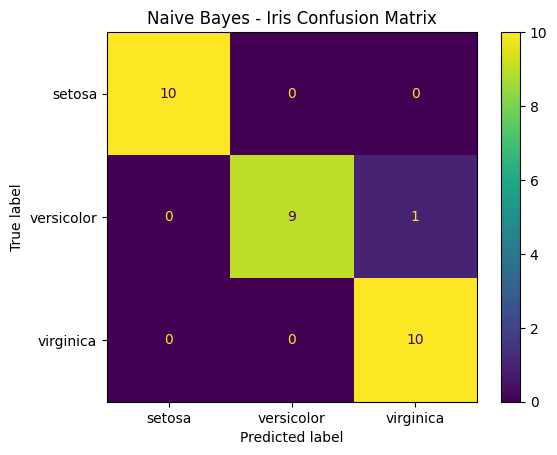

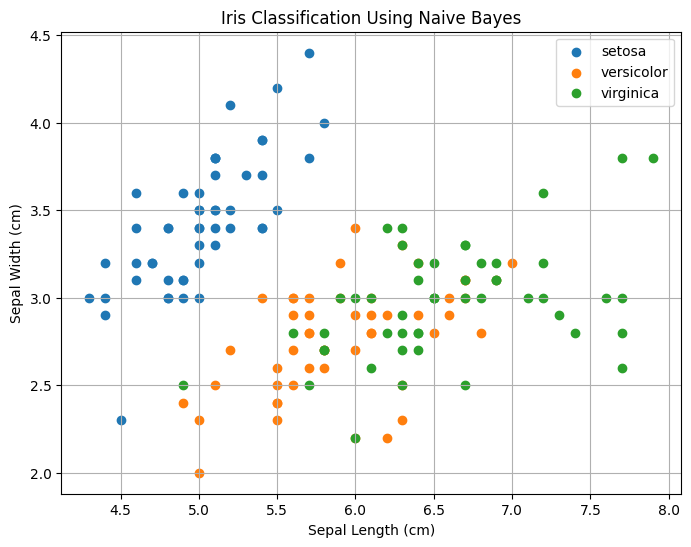


New Flower Measurements:
Sepal Length = 5.1 cm
Sepal Width  = 3.5 cm
Petal Length = 1.4 cm
Petal Width  = 0.2 cm

Predicted Flower Species:
setosa


In [ ]:
# ---------------------------------------------------
# 15. IRIS FLOWER CLASSIFICATION USING NAIVE BAYES
# ---------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


# ---------------------------------------------------
# STEP 1: Load Iris Dataset
# ---------------------------------------------------

iris = load_iris()

X = iris.data
y = iris.target

print("Iris Flower Classification Using Naive Bayes")
print("---------------------------------------------")

print("\nDataset Shape:", X.shape)

print("Flower Classes:", iris.target_names)


# ---------------------------------------------------
# STEP 2: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ---------------------------------------------------
# STEP 3: Create Naive Bayes Model
# ---------------------------------------------------

model = GaussianNB()


# ---------------------------------------------------
# STEP 4: Train the Model
# ---------------------------------------------------

model.fit(X_train, y_train)


# ---------------------------------------------------
# STEP 5: Predict Flower Species
# ---------------------------------------------------

y_pred = model.predict(X_test)


# ---------------------------------------------------
# STEP 6: Calculate Accuracy
# ---------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:")
print(round(accuracy * 100, 2), "%")


# ---------------------------------------------------
# STEP 7: Display Predictions
# ---------------------------------------------------

print("\nActual vs Predicted:")
print("--------------------")

for i in range(10):

    actual = iris.target_names[y_test[i]]

    predicted = iris.target_names[y_pred[i]]

    print("Actual:", actual, "| Predicted:", predicted)


# ---------------------------------------------------
# STEP 8: Display Confusion Matrix
# ---------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2]
)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot()

plt.title("Naive Bayes - Iris Confusion Matrix")

plt.show()


# ---------------------------------------------------
# STEP 9: Visualize Iris Dataset
# ---------------------------------------------------

plt.figure(figsize=(8, 6))

for i, name in enumerate(iris.target_names):

    plt.scatter(
        X[y == i, 0],
        X[y == i, 1],
        label=name
    )

plt.xlabel("Sepal Length (cm)")

plt.ylabel("Sepal Width (cm)")

plt.title("Iris Classification Using Naive Bayes")

plt.legend()

plt.grid(True)

plt.show()


# ---------------------------------------------------
# STEP 10: Classify a New Flower
# ---------------------------------------------------

new_flower = np.array([
    [5.1, 3.5, 1.4, 0.2]
])

prediction = model.predict(new_flower)

print("\nNew Flower Measurements:")
print("Sepal Length = 5.1 cm")
print("Sepal Width  = 3.5 cm")
print("Petal Length = 1.4 cm")
print("Petal Width  = 0.2 cm")

print("\nPredicted Flower Species:")

print(iris.target_names[prediction[0]])

Classification Algorithm Comparison
-----------------------------------
Dataset: Iris
Total Samples: 150
Total Features: 4
Classes: ['setosa' 'versicolor' 'virginica']

Algorithm: Decision Tree
Accuracy: 93.33 %
Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Algorithm: KNN
Accuracy: 93.33 %
Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Algorithm: Naive Bayes
Accuracy: 96.67 %
Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Algorithm: Logistic Regression
Accuracy: 93.33 %
Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Algorithm: SVM
Accuracy: 96.67 %
Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

FINAL PERFORMANCE COMPARISON
          Algorithm  Accuracy (%)
        Naive Bayes         96.67
                SVM         96.67
      Decision Tree         93.33
                KNN         93.33
Logistic Regression         93.33


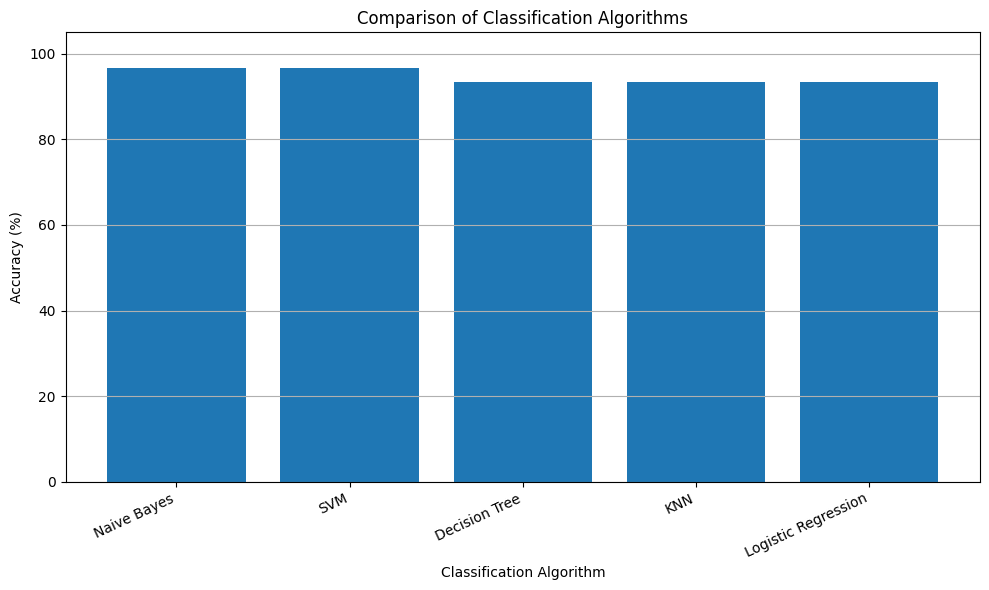

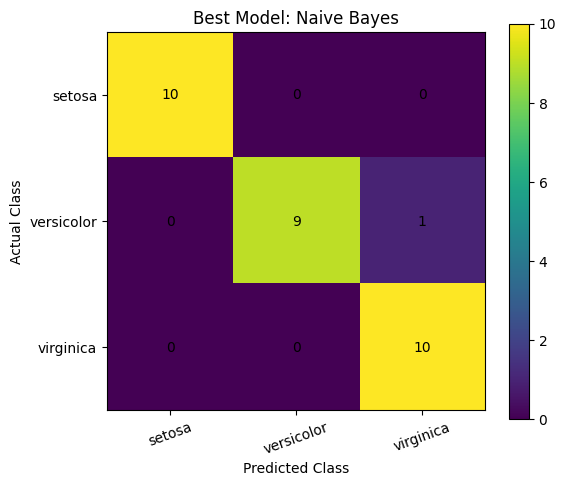


Best Performing Algorithm:
Naive Bayes
Accuracy: 96.67 %


In [ ]:
# ---------------------------------------------------
# 16. COMPARISON OF CLASSIFICATION ALGORITHMS
# ---------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, confusion_matrix


# ---------------------------------------------------
# STEP 1: Load Dataset
# ---------------------------------------------------

iris = load_iris()

X = iris.data
y = iris.target

print("Classification Algorithm Comparison")
print("-----------------------------------")
print("Dataset: Iris")
print("Total Samples:", len(X))
print("Total Features:", X.shape[1])
print("Classes:", iris.target_names)


# ---------------------------------------------------
# STEP 2: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ---------------------------------------------------
# STEP 3: Define Classification Algorithms
# ---------------------------------------------------

models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Naive Bayes": GaussianNB(),

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC()
    )
}


# ---------------------------------------------------
# STEP 4: Train and Evaluate Models
# ---------------------------------------------------

results = []

confusion_matrices = {}

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Calculate confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1, 2]
    )

    results.append({
        "Algorithm": name,
        "Accuracy (%)": round(accuracy * 100, 2)
    })

    confusion_matrices[name] = cm

    print("\nAlgorithm:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Confusion Matrix:")
    print(cm)


# ---------------------------------------------------
# STEP 5: Display Comparison Table
# ---------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy (%)",
    ascending=False
)

print("\n===================================")
print("FINAL PERFORMANCE COMPARISON")
print("===================================")

print(results_df.to_string(index=False))


# ---------------------------------------------------
# STEP 6: Plot Accuracy Comparison
# ---------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    results_df["Algorithm"],
    results_df["Accuracy (%)"]
)

plt.xlabel("Classification Algorithm")
plt.ylabel("Accuracy (%)")

plt.title("Comparison of Classification Algorithms")

plt.xticks(rotation=25, ha="right")

plt.ylim(0, 105)

plt.grid(axis="y")

plt.tight_layout()

plt.show()


# ---------------------------------------------------
# STEP 7: Display Confusion Matrix of Best Model
# ---------------------------------------------------

best_model_name = results_df.iloc[0]["Algorithm"]

best_cm = confusion_matrices[best_model_name]

plt.figure(figsize=(6, 5))

plt.imshow(best_cm, interpolation="nearest")

plt.title("Best Model: " + best_model_name)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    [0, 1, 2],
    iris.target_names,
    rotation=20
)

plt.yticks(
    [0, 1, 2],
    iris.target_names
)

for i in range(3):
    for j in range(3):
        plt.text(
            j,
            i,
            best_cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.tight_layout()

plt.show()


# ---------------------------------------------------
# STEP 8: Display Best Algorithm
# ---------------------------------------------------

print("\nBest Performing Algorithm:")

print(best_model_name)

print(
    "Accuracy:",
    results_df.iloc[0]["Accuracy (%)"],
    "%"
)

MOBILE PRICE PREDICTION
-----------------------
Total Samples: 500
Training Samples: 400
Testing Samples: 100
Model Accuracy: 77.0 %

NEW MOBILE SPECIFICATIONS
 RAM_GB  Storage_GB  Battery_mAh  Camera_MP  5G
      8         128         5000         50   1
Predicted Price Range: Medium Price


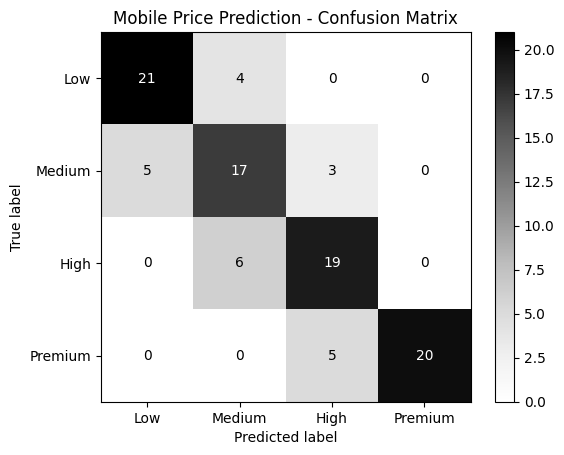

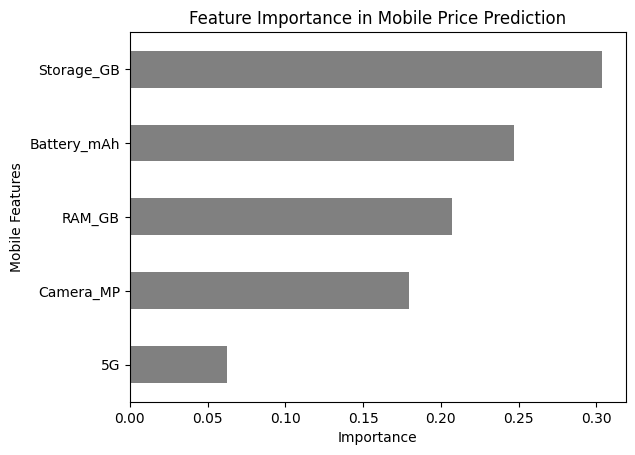

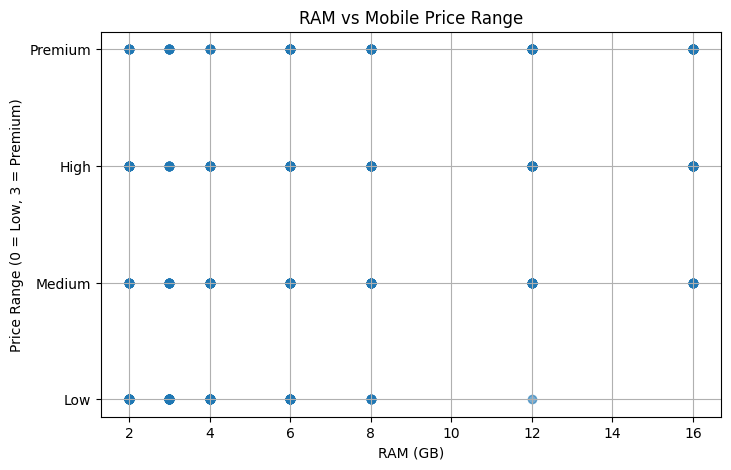

In [ ]:
# Mobile Price Prediction using Random Forest

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Step 1: Generate a sample dataset
np.random.seed(42)

n = 500

data = pd.DataFrame({
    'RAM_GB': np.random.choice([2, 3, 4, 6, 8, 12, 16], n),
    'Storage_GB': np.random.choice([32, 64, 128, 256, 512], n),
    'Battery_mAh': np.random.randint(2500, 7001, n),
    'Camera_MP': np.random.choice([8, 12, 16, 32, 48, 50, 64, 108], n),
    '5G': np.random.choice([0, 1], n)
})

# Step 2: Create price categories based on mobile specifications
score = (
    data['RAM_GB'] * 0.45 +
    data['Storage_GB'] * 0.02 +
    data['Battery_mAh'] * 0.001 +
    data['Camera_MP'] * 0.05 +
    data['5G'] * 2
    + np.random.normal(0, 0.5, n)
)

# Divide phones into four price ranges
data['Price_Range'] = np.digitize(
    score,
    bins=np.quantile(score, [0.25, 0.50, 0.75])
)

# Step 3: Select input features and target
X = data.drop('Price_Range', axis=1)
y = data['Price_Range']

# Step 4: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 5: Train the Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

# Step 6: Make predictions
y_pred = model.predict(X_test)

# Step 7: Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("MOBILE PRICE PREDICTION")
print("-----------------------")
print("Total Samples:", len(data))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Display price range meanings
price_ranges = {
    0: "Low Price",
    1: "Medium Price",
    2: "High Price",
    3: "Premium Price"
}

# Predict the price range of a new mobile
new_mobile = pd.DataFrame([{
    'RAM_GB': 8,
    'Storage_GB': 128,
    'Battery_mAh': 5000,
    'Camera_MP': 50,
    '5G': 1
}])

prediction = model.predict(new_mobile)[0]

print("\nNEW MOBILE SPECIFICATIONS")
print(new_mobile.to_string(index=False))
print("Predicted Price Range:", price_ranges[prediction])

# Step 8: Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Low', 'Medium', 'High', 'Premium']
).plot(cmap='Greys')

plt.title("Mobile Price Prediction - Confusion Matrix")
plt.show()

# Step 9: Plot feature importance
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values()

importance.plot(kind='barh', color='gray')

plt.title("Feature Importance in Mobile Price Prediction")
plt.xlabel("Importance")
plt.ylabel("Mobile Features")
plt.show()

# Step 10: Plot RAM against price range
plt.figure(figsize=(8, 5))

plt.scatter(
    data['RAM_GB'],
    data['Price_Range'],
    alpha=0.6
)

plt.title("RAM vs Mobile Price Range")
plt.xlabel("RAM (GB)")
plt.ylabel("Price Range (0 = Low, 3 = Premium)")
plt.yticks([0, 1, 2, 3], ['Low', 'Medium', 'High', 'Premium'])
plt.grid(True)
plt.show()

PERCEPTRON-BASED IRIS CLASSIFICATION
-----------------------------------
Total Samples: 150
Training Samples: 120
Testing Samples: 30
Model Accuracy: 76.67 %

New Flower Measurements:
Sepal Length: 5.1 cm
Sepal Width: 3.5 cm
Petal Length: 1.4 cm
Petal Width: 0.2 cm
Predicted Species: setosa


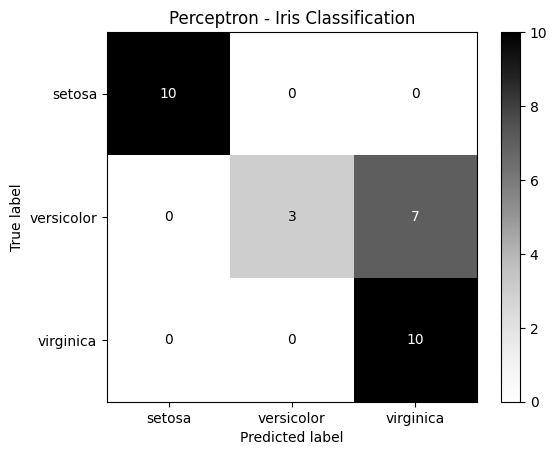

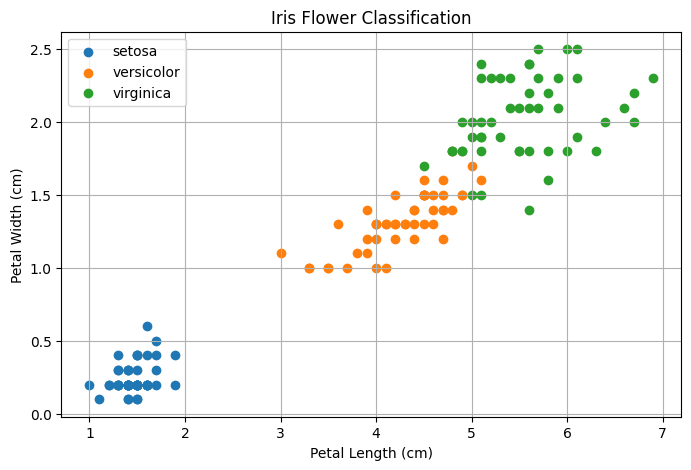

In [ ]:
# Perceptron-Based Iris Classification

import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Step 1: Load the Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

# Step 2: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 3: Create and train the Perceptron model
model = Perceptron(max_iter=1000, random_state=42)

model.fit(X_train, y_train)

# Step 4: Predict flower species
y_pred = model.predict(X_test)

# Step 5: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("PERCEPTRON-BASED IRIS CLASSIFICATION")
print("-----------------------------------")
print("Total Samples:", len(X))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Step 6: Predict a new flower
new_flower = [[5.1, 3.5, 1.4, 0.2]]

prediction = model.predict(new_flower)[0]

print("\nNew Flower Measurements:")
print("Sepal Length: 5.1 cm")
print("Sepal Width: 3.5 cm")
print("Petal Length: 1.4 cm")
print("Petal Width: 0.2 cm")

print("Predicted Species:", iris.target_names[prediction])

# Step 7: Display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
).plot(cmap="Greys")

plt.title("Perceptron - Iris Classification")
plt.show()

# Step 8: Visualize actual flower classes
plt.figure(figsize=(8, 5))

for species in range(3):
    plt.scatter(
        X[y == species, 2],
        X[y == species, 3],
        label=iris.target_names[species]
    )

plt.title("Iris Flower Classification")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.grid(True)
plt.show()

BANK LOAN PREDICTION
--------------------

Sample Dataset:
   Income  Credit_Score  Employment  Existing_Debt  Loan_Approved
0   25000           550           0          20000              0
1   30000           600           0          25000              0
2   45000           650           1          15000              1
3   50000           700           1          10000              1
4   60000           720           1          12000              1

Training Samples: 15
Testing Samples: 5
Model Accuracy: 80.0 %

NEW APPLICANT
Income: 60000
Credit Score: 720
Employment: Employed
Existing Debt: 10000
Predicted Result: Loan Approved
Approval Probability: 100.0 %


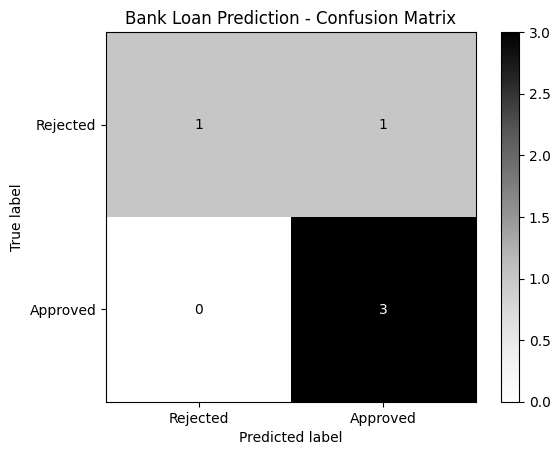

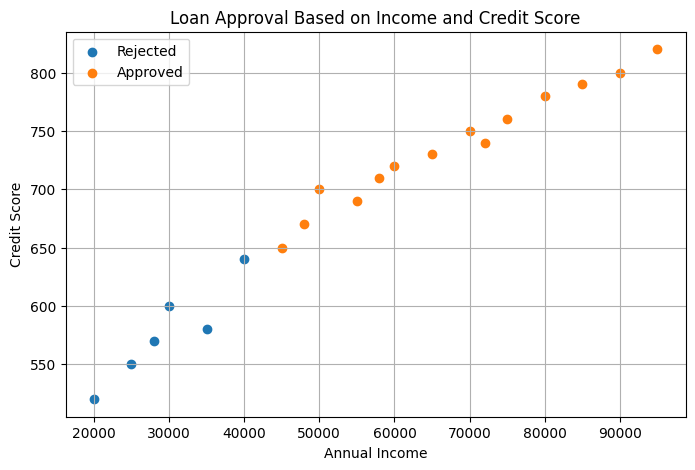

In [ ]:
# Bank Loan Prediction using Naive Bayes

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Step 1: Create a sample dataset
data = pd.DataFrame({
    'Income': [
        25000, 30000, 45000, 50000, 60000,
        70000, 80000, 35000, 55000, 90000,
        20000, 40000, 65000, 75000, 85000,
        28000, 48000, 58000, 72000, 95000
    ],
    'Credit_Score': [
        550, 600, 650, 700, 720,
        750, 780, 580, 690, 800,
        520, 640, 730, 760, 790,
        570, 670, 710, 740, 820
    ],
    'Employment': [
        0, 0, 1, 1, 1,
        1, 1, 0, 1, 1,
        0, 1, 1, 1, 1,
        0, 1, 1, 1, 1
    ],
    'Existing_Debt': [
        20000, 25000, 15000, 10000, 12000,
        8000, 5000, 30000, 18000, 7000,
        25000, 20000, 15000, 10000, 9000,
        28000, 16000, 14000, 11000, 6000
    ],
    'Loan_Approved': [
        0, 0, 1, 1, 1,
        1, 1, 0, 1, 1,
        0, 0, 1, 1, 1,
        0, 1, 1, 1, 1
    ]
})

# Employment: 0 = Unemployed, 1 = Employed
# Loan_Approved: 0 = Rejected, 1 = Approved

print("BANK LOAN PREDICTION")
print("--------------------")
print("\nSample Dataset:")
print(data.head())

# Step 2: Select features and target
X = data[['Income', 'Credit_Score', 'Employment', 'Existing_Debt']]
y = data['Loan_Approved']

# Step 3: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Step 4: Train the Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

# Step 5: Predict loan approval
y_pred = model.predict(X_test)

# Step 6: Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Step 7: Predict for a new applicant
new_applicant = pd.DataFrame([{
    'Income': 60000,
    'Credit_Score': 720,
    'Employment': 1,
    'Existing_Debt': 10000
}])

prediction = model.predict(new_applicant)[0]
probabilities = model.predict_proba(new_applicant)[0]

print("\nNEW APPLICANT")
print("Income: 60000")
print("Credit Score: 720")
print("Employment: Employed")
print("Existing Debt: 10000")

if prediction == 1:
    print("Predicted Result: Loan Approved")
else:
    print("Predicted Result: Loan Rejected")

print("Approval Probability:", round(probabilities[1] * 100, 2), "%")

# Step 8: Display confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Rejected', 'Approved']
).plot(cmap='Greys')

plt.title("Bank Loan Prediction - Confusion Matrix")
plt.show()

# Step 9: Visualize income and loan approval
plt.figure(figsize=(8, 5))

for status, label in [(0, 'Rejected'), (1, 'Approved')]:
    subset = data[data['Loan_Approved'] == status]

    plt.scatter(
        subset['Income'],
        subset['Credit_Score'],
        label=label
    )

plt.title("Loan Approval Based on Income and Credit Score")
plt.xlabel("Annual Income")
plt.ylabel("Credit Score")
plt.legend()
plt.grid(True)
plt.show()

FUTURE SALES PREDICTION
-----------------------

Historical Sales Data:
 Month  Sales
     1    120
     2    135
     3    128
     4    145
     5    160
     6    155
     7    175
     8    180
     9    170
    10    195
    11    205
    12    220
    13    210
    14    230
    15    225
    16    245
    17    260
    18    250
    19    275
    20    285
    21    280
    22    300
    23    315
    24    330

MODEL EVALUATION
----------------
Mean Absolute Error: 6.94
Mean Squared Error: 73.41
R2 Score: 0.98

FUTURE SALES PREDICTION
-----------------------
Month 25: Predicted Sales = 323.69
Month 26: Predicted Sales = 332.28
Month 27: Predicted Sales = 340.87
Month 28: Predicted Sales = 349.47
Month 29: Predicted Sales = 358.06
Month 30: Predicted Sales = 366.65


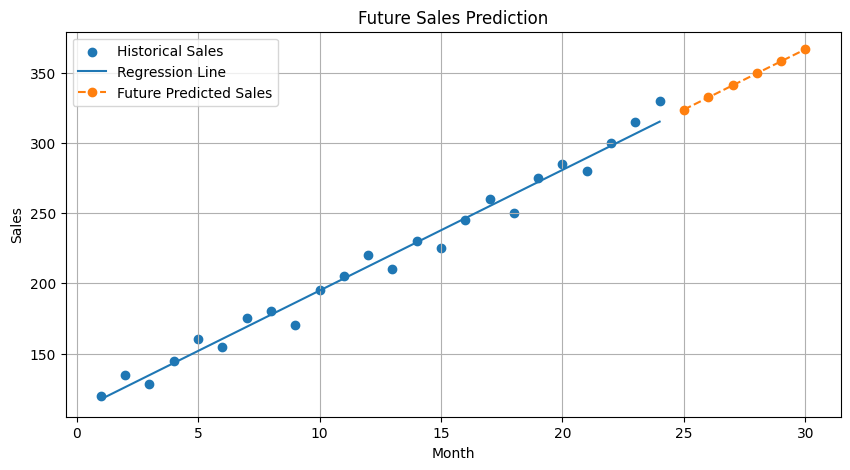

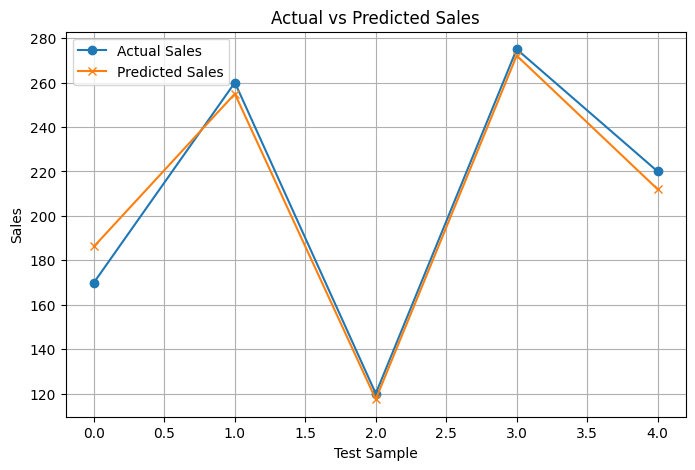

In [ ]:
# Future Sales Prediction using Linear Regression

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Step 1: Create sample historical sales data
data = pd.DataFrame({
    'Month': list(range(1, 25)),
    'Sales': [
        120, 135, 128, 145, 160, 155,
        175, 180, 170, 195, 205, 220,
        210, 230, 225, 245, 260, 250,
        275, 285, 280, 300, 315, 330
    ]
})

print("FUTURE SALES PREDICTION")
print("-----------------------")
print("\nHistorical Sales Data:")
print(data.to_string(index=False))

# Step 2: Select features and target
X = data[['Month']]
y = data['Sales']

# Step 3: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Step 4: Train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 5: Predict sales for test data
y_pred = model.predict(X_test)

# Step 6: Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nMODEL EVALUATION")
print("----------------")
print("Mean Absolute Error:", round(mae, 2))
print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 2))

# Step 7: Predict sales for the next 6 months
future_months = pd.DataFrame({
    'Month': list(range(25, 31))
})

future_sales = model.predict(future_months)

print("\nFUTURE SALES PREDICTION")
print("-----------------------")

for month, sales in zip(future_months['Month'], future_sales):
    print(f"Month {month}: Predicted Sales = {sales:.2f}")

# Step 8: Plot historical and predicted sales
plt.figure(figsize=(10, 5))

plt.scatter(
    data['Month'],
    data['Sales'],
    label='Historical Sales'
)

plt.plot(
    data['Month'],
    model.predict(X),
    label='Regression Line'
)

plt.plot(
    future_months['Month'],
    future_sales,
    marker='o',
    linestyle='--',
    label='Future Predicted Sales'
)

plt.title("Future Sales Prediction")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

# Step 9: Compare actual and predicted test sales
plt.figure(figsize=(8, 5))

plt.plot(
    range(len(y_test)),
    y_test.values,
    marker='o',
    label='Actual Sales'
)

plt.plot(
    range(len(y_pred)),
    y_pred,
    marker='x',
    label='Predicted Sales'
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Test Sample")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()